In [3]:
import pandas as pd
import matplotlib.pyplot as plt

taxi = pd.read_csv('/datasets/project_sql_result_01.csv')
dropoffs = pd.read_csv('/datasets/project_sql_result_04.csv')

In [4]:
print(taxi.head())
print(taxi.info())

print(dropoffs.head())
print(dropoffs.info())

                      company_name  trips_amount
0                        Flash Cab         19558
1        Taxi Affiliation Services         11422
2                Medallion Leasing         10367
3                       Yellow Cab          9888
4  Taxi Affiliation Service Yellow          9299
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB
None
  dropoff_location_name  average_trips
0                  Loop   10727.466667
1           River North    9523.666667
2         Streeterville    6664.666667
3             West Loop    5163.666667
4                O'Hare    2546.900000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  D

In [5]:


top_10_dropoffs = dropoffs.sort_values(by='average_trips', ascending=False).head(10)

print(top_10_dropoffs)



  dropoff_location_name  average_trips
0                  Loop   10727.466667
1           River North    9523.666667
2         Streeterville    6664.666667
3             West Loop    5163.666667
4                O'Hare    2546.900000
5             Lake View    2420.966667
6            Grant Park    2068.533333
7         Museum Campus    1510.000000
8            Gold Coast    1364.233333
9    Sheffield & DePaul    1259.766667


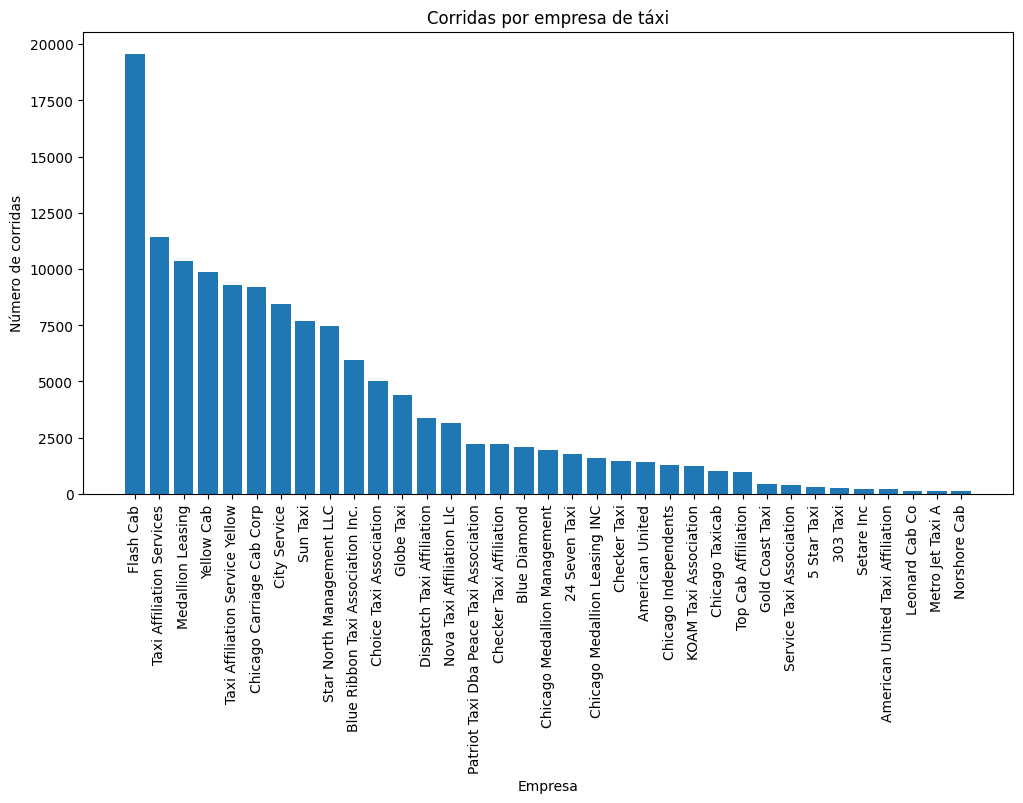

In [7]:
taxi_filtered = taxi[taxi['trips_amount'] > 100]

taxi_sorted = taxi_filtered.sort_values(
    by='trips_amount',
    ascending=False
)

plt.figure(figsize=(12,6))

plt.bar(
    taxi_sorted['company_name'],
    taxi_sorted['trips_amount']
)

plt.xticks(rotation=90)

plt.title('Corridas por empresa de táxi')
plt.xlabel('Empresa')
plt.ylabel('Número de corridas')

plt.show()

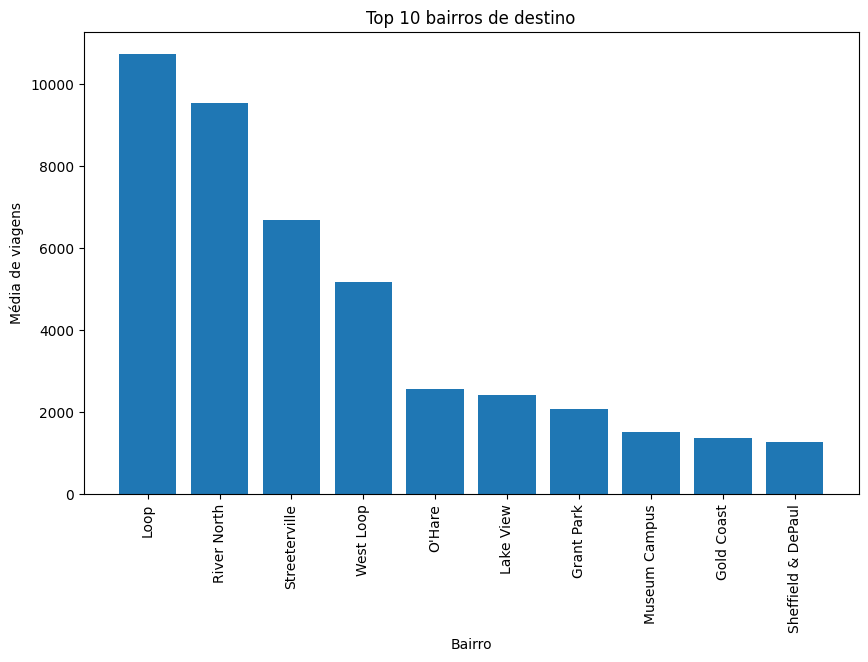

In [21]:
plt.figure(figsize=(10,6))
plt.bar(top_10_dropoffs['dropoff_location_name'], top_10_dropoffs['average_trips'])
plt.xticks(rotation=90)
plt.title('Top 10 bairros de destino')
plt.xlabel('Bairro')
plt.ylabel('Média de viagens')
plt.show()

As empresas de táxi têm distribuição desigual de corridas, com algumas dominando o mercado.
As empresas mais populares concentram grande parte das viagens.
Os bairros de destino mais frequentes mostram alta concentração em poucas áreas da cidade.
Isso sugere que a demanda de táxi é fortemente centralizada em regiões específicas de Chicago.

In [8]:
import pandas as pd
import scipy.stats as st

df = pd.read_csv('/datasets/project_sql_result_07.csv')

df['start_ts'] = pd.to_datetime(df['start_ts'])
df['day_of_week'] = df['start_ts'].dt.dayofweek

saturdays = df[df['day_of_week'] == 5]

In [9]:
rainy = saturdays[saturdays['weather_conditions'] == 'Bad']['duration_seconds']
good = saturdays[saturdays['weather_conditions'] == 'Good']['duration_seconds']

In [11]:
var_bad = rainy.var()
var_good = good.var()

levene_stat, levene_pvalue = st.levene(rainy, good, center='median')

print("Variância dias chuvosos:", var_bad)
print("Variância dias bons:", var_good)
print("Estatística de Levene:", levene_stat)
print("p-value de Levene:", levene_pvalue)

Variância dias chuvosos: 520294.086002483
Variância dias bons: 576382.009689509
Estatística de Levene: 0.38853489683656073
p-value de Levene: 0.5332038671974493


In [12]:
t_stat, p_value = st.ttest_ind(rainy, good, equal_var=False)

print("Estatística t:", t_stat)
print("p-value:", p_value)

Estatística t: 7.186034288068629
p-value: 6.738994326108734e-12


O teste de Levene indicou que não há evidência de diferença entre as variâncias dos grupos (p-value = 0.533). Em seguida, o teste t de Student mostrou diferença estatisticamente significativa entre a duração das viagens em dias chuvosos e dias sem chuva (p-value < 0.05), levando à rejeição da hipótese nula.

Hipótese nula (H0):
A duração média das corridas é a mesma em sábados chuvosos e não chuvosos.

Hipótese alternativa (H1):
A duração média das corridas é diferente em sábados chuvosos e não chuvosos.

In [18]:
alpha = 0.05

results = stats.ttest_ind(rain, good)

print('p-value:', results.pvalue)

if results.pvalue < alpha:
    print("Rejeitamos a hipótese nula")
else:
    print("Não rejeitamos a hipótese nula")

p-value: 6.517970327099473e-12
Rejeitamos a hipótese nula


Critério usado

Usei o teste t para amostras independentes, pois estou comparando as médias de dois grupos distintos (sábados chuvosos e não chuvosos), com dados numéricos (duração das corridas), e os grupos são independentes.

Nível de significância

α = 0.05, o que representa um risco de 5% de rejeitar a hipótese nula quando ela é verdadeira.

Conclusão

O valor-p obtido foi extremamente pequeno (6.52e-12), muito inferior ao nível de significância (0.05). Portanto, rejeitamos a hipótese nula.

Isso indica que há evidências estatísticas de que a duração média das corridas do Loop para o Aeroporto Internacional O’Hare difere entre sábados chuvosos e não chuvosos.